# Shallow Neural Networks

The purpose of this notebook is to gain some familiarity with shallow neural networks with 1D inputs.

It works through an example similar to figures in the <font color="red"> lecture slides (LS) 10.Machine Learning.pdf (p.27, 28, and 32) </font> and experiments. <br>

**NOTE**: Work through the cells below, running each cell in turn. 


In [3]:
# Imports math library
import numpy as np
# Imports plotting library
import matplotlib.pyplot as plt

Let's first construct the shallow neural network with one input, three hidden units, and one output.

### Define the Rectified Linear Unit (ReLU) function
#### (1) Write code to implement the **ReLU** and compute the activation at the hidden unit from the preactivation.

This should work on every element of the ndarray "preactivation" at once.

One way to do this is with the ndarray `clip` function: 
https://numpy.org/doc/stable/reference/generated/numpy.ndarray.clip.html


In [5]:
def ReLU(preactivation):
    
    # Replace the following code properly
    activation = np.zeros_like(preactivation);

    return activation

Let's make an array of inputs.

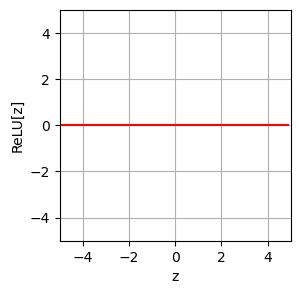

In [7]:
# array of inputs
z = np.arange(-5,5,0.1)
RelU_z = ReLU(z)

# Plot the ReLU function
fig, ax = plt.subplots(figsize=(3,3))
ax.plot(z,RelU_z,'r-')
ax.set_xlim([-5,5]);ax.set_ylim([-5,5])
ax.set_xlabel('z'); ax.set_ylabel('ReLU[z]')
ax.set_aspect('equal')
ax.grid()
plt.show()

#### (2) Define a shallow neural network with, one input, one output, and three hidden units (LS p.29).
**NOTE**: Fill or modify the code between lines like:<br>
################################################ <br>
\#    you need to do something here. <br>
################################################

In [19]:
import numpy as np

def shallow_1_1_3(x, activation_fn, phi_0, phi_1, phi_2, phi_3, theta_10, theta_11, theta_20, theta_21, theta_30, theta_31):    
    ################################################
    # Compute the pre-activations for each hidden unit (using the provided theta parameters)
    pre_1 = theta_10 * x + theta_11
    pre_2 = theta_20 * x + theta_21
    pre_3 = theta_30 * x + theta_31
    ################################################

    # Apply the activation function (e.g., ReLU)
    act_1 = activation_fn(pre_1)
    act_2 = activation_fn(pre_2)
    act_3 = activation_fn(pre_3)

    ################################################
    # Weight the activations using phi parameters
    w_act_1 = phi_1 * act_1
    w_act_2 = phi_2 * act_2
    w_act_3 = phi_3 * act_3
    ################################################

    # Combine the weighted activations and add phi_0 to create the output
    y = phi_0 + w_act_1 + w_act_2 + w_act_3

    ################################################        
    # Return everything we have calculated
    return y, pre_1, pre_2, pre_3, act_1, act_2, act_3, w_act_1, w_act_2, w_act_3


The following code is to plot the shallow neural network. We'll assume input in is range [0,1] and output [-1,1]. <br>
If the plot_all flag is set to true, then we'll plot all the intermediate stages as in Figures (p.27, 28).

In [ ]:
def plot_neural(x, y, pre_1, pre_2, pre_3, act_1, act_2, act_3, w_act_1, w_act_2, w_act_3, plot_all=False, x_data=None, y_data=None):
    # Plot intermediate plots if flag set
    if plot_all:
        fig, ax = plt.subplots(3,3)
        fig.set_size_inches(8.5, 8.5)
        fig.tight_layout(pad=3.0)
        ax[0,0].plot(x,pre_1,'r-'); ax[0,0].set_ylabel('Preactivation')
        ax[0,1].plot(x,pre_2,'b-'); ax[0,1].set_ylabel('Preactivation')
        ax[0,2].plot(x,pre_3,'g-'); ax[0,2].set_ylabel('Preactivation')
        ax[1,0].plot(x,act_1,'r-'); ax[1,0].set_ylabel('Activation')
        ax[1,1].plot(x,act_2,'b-'); ax[1,1].set_ylabel('Activation')
        ax[1,2].plot(x,act_3,'g-'); ax[1,2].set_ylabel('Activation')
        ax[2,0].plot(x,w_act_1,'r-'); ax[2,0].set_ylabel('Weighted Act')
        ax[2,1].plot(x,w_act_2,'b-'); ax[2,1].set_ylabel('Weighted Act')
        ax[2,2].plot(x,w_act_3,'g-'); ax[2,2].set_ylabel('Weighted Act')

    for plot_y in range(3):
        for plot_x in range(3):
            ax[plot_y,plot_x].set_xlim([0,1]);ax[plot_x,plot_y].set_ylim([-1,1])
            ax[plot_y,plot_x].set_aspect(0.5)
            ax[plot_y,plot_x].grid(True)
        ax[2,plot_y].set_xlabel('Input, $x$');
    plt.show()

    fig, ax = plt.subplots()
    ax.plot(x,y)
    ax.set_xlabel('Input, $x$'); ax.set_ylabel('Output, $y$')
    ax.set_xlim([0,1]);ax.set_ylim([-1,1])
    ax.set_aspect(0.5)
    if x_data is not None:
        ax.plot(x_data, y_data, 'mo')
        for i in range(len(x_data)):
            ax.plot(x_data[i], y_data[i],)
    ax.grid(True)
    plt.show()

Now lets define some parameters and run the neural network.

In [ ]:
theta_10 =  0.3 ; theta_11 = -1.0
theta_20 = -1.0  ; theta_21 = 2.0
theta_30 = -0.5  ; theta_31 = 0.65
phi_0 = -0.3; phi_1 = 2.0; phi_2 = -1.0; phi_3 = 7.0

# Define a range of input values
x = np.arange(0,1,0.01)

# We run the neural network for each of these input values
y, pre_1, pre_2, pre_3, act_1, act_2, act_3, w_act_1, w_act_2, w_act_3 = \
    shallow_1_1_3(x, ReLU, phi_0,phi_1,phi_2,phi_3, theta_10, theta_11, theta_20, theta_21, theta_30, theta_31)

# And then plot it
plot_neural(x, y, pre_1, pre_2, pre_3, act_1, act_2, act_3, w_act_1, w_act_2, w_act_3, plot_all=True)

If your code is correct, then the final output should look like this:


Now let's play with the parameters to make sure we understand how they work.  The original  parameters were:

$\theta_{10} =  0.3$ ; $\theta_{11} = -1.0$<br>
$\theta_{20} =  -1.0$ ; $\theta_{21} = 2.0$<br>
$\theta_{30} =  -0.5$ ; $\theta_{31} = 0.65$<br>
$\phi_0 = -0.3; \phi_1 = 2.0; \phi_2 = -1.0; \phi_3 = 7.0$

In [ ]:
theta_10 =  0.3 ; theta_11 = -1.0
theta_20 = -1.0  ; theta_21 = 2.0
theta_30 = -0.5  ; theta_31 = 0.65
phi_0 = -0.3; phi_1 = 2.0; phi_2 = -1.0; phi_3 = 7.0

# Define a range of input values
x = np.arange(0,1,0.01)

# We run the neural network for each of these input values
y, pre_1, pre_2, pre_3, act_1, act_2, act_3, w_act_1, w_act_2, w_act_3 = \
    shallow_1_1_3(x, ReLU, phi_0,phi_1,phi_2,phi_3, theta_10, theta_11, theta_20, theta_21, theta_30, theta_31)

# And then plot it
plot_neural(x, y, pre_1, pre_2, pre_3, act_1, act_2, act_3, w_act_1, w_act_2, w_act_3, plot_all=True)

### Least squares loss

Now let's consider fitting the network to data.  First we need to define the loss function.  We'll use the least squares loss:

\begin{equation}
L[\boldsymbol\phi] = \sum_{i=1}^{I}(y_{i}-\text{f}[x_{i},\boldsymbol\phi])^2
\end{equation}

where $(x_i,y_i)$ is an input/output training pair and $\text{f}[\bullet,\boldsymbol\phi]$ is the neural network with parameters $\boldsymbol\phi$.  The first term in the brackets is the ground truth output and the second term is the prediction of the model

#### (3) Replace the line below to compute the sum of squared.
The least squares function will show you the differences between the real values of y and the predicted values from the model f[x_i,phi].
(see LS p.12 for its definition). 

You will need to use the function `np.sum`. 

In [ ]:
# Least squares function
def least_squares_loss(y_train, y_predict):
    # Modify the following line to calculate the loss
    loss = 0

    return loss

#### (4) Now let's define some parameters, run the neural network, and compute the loss.

#### Manipulate the parameters (by hand!) to make the function fit the data better and try to reduce the loss to as small a number as possible.  

**Strategy to Reduce Loss**

1. Start with phi_0:

> It shifts the entire prediction vertically. <br>
> Try adjusting it up or down to match the average of y_train.

2. Adjust phi_1, phi_2, phi_3:

> These scale the contributions of the hidden units. <br>
> Try shrinking large bumps or flipping dips that are off from the data.

3. Tweak theta_ij values:

> These control where the ReLU units activate. <br>
> Moving joints left or right can help the model bend the function where the data changes sharply.

It's not that easy, so don't spend too much time on this!

In [ ]:
#####################################################
# There are parameters, run the neural network, and compute the loss
theta_10 =  0.3 ; theta_11 = -1.0
theta_20 = -1.0  ; theta_21 = 2.0
theta_30 = -0.5  ; theta_31 = 0.65
phi_0 = -0.3; phi_1 = 2.0; phi_2 = -1.0; phi_3 = 7.0
#####################################################

# Define a range of input values
x = np.arange(0,1,0.01)

x_train = np.array([0.09291784,0.46809093,0.93089486,0.67612654,0.73441752,0.86847339,\
                   0.49873225,0.51083168,0.18343972,0.99380898,0.27840809,0.38028817,\
                   0.12055708,0.56715537,0.92005746,0.77072270,0.85278176,0.05315950,\
                   0.87168699,0.58858043])
y_train = np.array([-0.15934537,0.18195445,0.451270150,0.13921448,0.09366691,0.30567674,\
                    0.372291170,0.40716968,-0.08131792,0.41187806,0.36943738,0.3994327,\
                    0.019062570,0.35820410,0.452564960,-0.0183121,0.02957665,-0.24354444, \
                    0.148038840,0.26824970])

# We run the neural network for each of these input values
y, pre_1, pre_2, pre_3, act_1, act_2, act_3, w_act_1, w_act_2, w_act_3 = \
    shallow_1_1_3(x, ReLU, phi_0,phi_1,phi_2,phi_3, theta_10, theta_11, theta_20, theta_21, theta_30, theta_31)
# And then plot it
plot_neural(x, y, pre_1, pre_2, pre_3, act_1, act_2, act_3, w_act_1, w_act_2, w_act_3, plot_all=True, x_data = x_train, y_data = y_train)

# Run the neural network on the training data
y_predict, *_ = shallow_1_1_3(x_train, ReLU, phi_0,phi_1,phi_2,phi_3, theta_10, theta_11, theta_20, theta_21, theta_30, theta_31)

# Compute the least squares loss and print it out
loss = least_squares_loss(y_train,y_predict)
print('Your Loss = %3.3f'%(loss))


### More than one input

Let's check an example similar to figure in LS p.32. 
<br> <br>


**Code to draw 2D function** <br>
Since we will have two inputs, so its plot will be 2D. <br>
Read the following code so you know what is going on, but you don't have to change it.


In [ ]:
def draw_2D_function(ax, x1_mesh, x2_mesh, y):
    pos = ax.contourf(x1_mesh, x2_mesh, y, levels=256 ,cmap = 'hot', vmin=-10,vmax=10.0)
    ax.set_xlabel('x1');ax.set_ylabel('x2')
    levels = np.arange(-10,10,1.0)
    ax.contour(x1_mesh, x2_mesh, y, levels, cmap='winter')

# Plot the shallow neural network.  We'll assume input in is range [0,10],[0,10] and output [-10,10]
def plot_neural_2_inputs(x1,x2, y, pre_1, pre_2, pre_3, act_1, act_2, act_3, w_act_1, w_act_2, w_act_3):
    fig, ax = plt.subplots(3,3)
    fig.set_size_inches(8.5, 8.5)
    fig.tight_layout(pad=3.0)
    draw_2D_function(ax[0,0], x1,x2,pre_1); ax[0,0].set_title('Preactivation')
    draw_2D_function(ax[0,1], x1,x2,pre_2); ax[0,1].set_title('Preactivation')
    draw_2D_function(ax[0,2], x1,x2,pre_3); ax[0,2].set_title('Preactivation')
    draw_2D_function(ax[1,0], x1,x2,act_1); ax[1,0].set_title('Activation')
    draw_2D_function(ax[1,1], x1,x2,act_2); ax[1,1].set_title('Activation')
    draw_2D_function(ax[1,2], x1,x2,act_3); ax[1,2].set_title('Activation')
    draw_2D_function(ax[2,0], x1,x2,w_act_1); ax[2,0].set_title('Weighted Act')
    draw_2D_function(ax[2,1], x1,x2,w_act_2); ax[2,1].set_title('Weighted Act')
    draw_2D_function(ax[2,2], x1,x2,w_act_3); ax[2,2].set_title('Weighted Act')
    plt.show()
    
    fig, ax = plt.subplots()
    draw_2D_function(ax,x1,x2,y)
    ax.set_title('Network output, $y$')
    ax.set_aspect(1.0)
    plt.show()

#### (5) Define a shallow neural network with, two input, one output, and three hidden units (LS p.32). 


In [ ]:
# Define a shallow neural network with, two input, one output, and three hidden units
def shallow_2_1_3(x1,x2, activation_fn, phi_0,phi_1,phi_2,phi_3, theta_10, theta_11,\
                  theta_12, theta_20, theta_21, theta_22, theta_30, theta_31, theta_32):

    ###########################################################################    
    # Replace the lines below to compute the three initial linear functions
    # (figure 3.8a-c) from the theta parameters.  These are the preactivations
    pre_1 = np.zeros_like(x1)
    pre_2 = np.zeros_like(x1)
    pre_3 = np.zeros_like(x1)
    ###########################################################################
    
    # Pass these through the ReLU function to compute the activations as in
    # figure 3.8 d-f
    act_1 = activation_fn(pre_1)
    act_2 = activation_fn(pre_2)
    act_3 = activation_fn(pre_3)

    ###########################################################################    
    # Replace the code below to weight the activations using phi1, phi2 and phi3
    # To create the equivalent of figure 3.8 g-i
    w_act_1 = np.zeros_like(x1)
    w_act_2 = np.zeros_like(x1)
    w_act_3 = np.zeros_like(x1)
    
    # Replace the code below to combing the weighted activations and add
    # phi_0 to create the output as in figure 3.8j
    y = np.zeros_like(x1)
    ###########################################################################
    
    # Return everything we have calculated
    return y, pre_1, pre_2, pre_3, act_1, act_2, act_3, w_act_1, w_act_2, w_act_3

The below plot code uses `meshgrid()`. You can check the details in # https://www.geeksforgeeks.org/numpy-meshgrid-function/.

In [ ]:
# Now lets define some parameters and run the neural network
theta_10 =  -4.0 ;  theta_11 = 0.9; theta_12 = 0.0
theta_20 =  5.0  ; theta_21 = -0.9 ; theta_22 = -0.5
theta_30 =  -7  ; theta_31 = 0.5; theta_32 = 0.9
phi_0 = 0.0; phi_1 = -2.0; phi_2 = 2.0; phi_3 = 1.5

x1 = np.arange(0.0, 10.0, 0.1)
x2 = np.arange(0.0, 10.0, 0.1)
x1,x2 = np.meshgrid(x1,x2)  

# We run the neural network for each of these input values
y, pre_1, pre_2, pre_3, act_1, act_2, act_3, w_act_1, w_act_2, w_act_3 = \
    shallow_2_1_3(x1,x2, ReLU, phi_0,phi_1,phi_2,phi_3, theta_10, theta_11, theta_12, theta_20, theta_21, theta_22, theta_30, theta_31, theta_32)
# And then plot it
plot_neural_2_inputs(x1,x2, y, pre_1, pre_2, pre_3, act_1, act_2, act_3, w_act_1, w_act_2, w_act_3)

How many different linear polytopes are made by this model?  Identify each in the network output.

---
Now we'll extend this model to have two outputs $y_1$ and $y_2$, each of which can be visualized with a separate heatmap. 

You will now have sets of parameters $\phi_{10}, \phi_{11}, \phi_{12}, \phi_{13}$ and $\phi_{20}, \phi_{21}, \phi_{22}, \phi_{23}$ that correspond to each of these outputs.

The following code plots the shallow neural network.

We'll assume input in is range [0,10],[0,10] and output [-10,10].

In [ ]:
def plot_neural_2_inputs_2_outputs(x1,x2, y1, y2, pre_1, pre_2, pre_3, act_1, act_2, act_3, w_act_11, w_act_12, w_act_13, w_act_21, w_act_22, w_act_23):
    
    # Plot intermediate plots if flag set
    fig, ax = plt.subplots(4,3)
    fig.set_size_inches(8.5, 8.5)
    fig.tight_layout(pad=3.0)
    draw_2D_function(ax[0,0], x1,x2,pre_1); ax[0,0].set_title('Preactivation')
    draw_2D_function(ax[0,1], x1,x2,pre_2); ax[0,1].set_title('Preactivation')
    draw_2D_function(ax[0,2], x1,x2,pre_3); ax[0,2].set_title('Preactivation')
    draw_2D_function(ax[1,0], x1,x2,act_1); ax[1,0].set_title('Activation')
    draw_2D_function(ax[1,1], x1,x2,act_2); ax[1,1].set_title('Activation')
    draw_2D_function(ax[1,2], x1,x2,act_3); ax[1,2].set_title('Activation')
    draw_2D_function(ax[2,0], x1,x2,w_act_11); ax[2,0].set_title('Weighted Act 1')
    draw_2D_function(ax[2,1], x1,x2,w_act_12); ax[2,1].set_title('Weighted Act 1')
    draw_2D_function(ax[2,2], x1,x2,w_act_13); ax[2,2].set_title('Weighted Act 1')
    draw_2D_function(ax[3,0], x1,x2,w_act_21); ax[3,0].set_title('Weighted Act 2')
    draw_2D_function(ax[3,1], x1,x2,w_act_22); ax[3,1].set_title('Weighted Act 2')
    draw_2D_function(ax[3,2], x1,x2,w_act_23); ax[3,2].set_title('Weighted Act 2')
    plt.show()
    
    fig, ax = plt.subplots()
    draw_2D_function(ax,x1,x2,y1)
    ax.set_title('Network output, $y_1$')
    ax.set_aspect(1.0)
    plt.show()
    
    fig, ax = plt.subplots()
    draw_2D_function(ax,x1,x2,y2)
    ax.set_title('Network output, $y_2$')
    ax.set_aspect(1.0)
    plt.show()

#### (6) Define a shallow neural network with, two inputs, two outputs, and three hidden units.


In [ ]:
def shallow_2_2_3(x1,x2, activation_fn, phi_10,phi_11,phi_12,phi_13, phi_20,phi_21,phi_22,phi_23, theta_10, theta_11,\
                  theta_12, theta_20, theta_21, theta_22, theta_30, theta_31, theta_32):

    ###################################
    # replace the dummy code below
    pre_1 = np.zeros_like(x1)
    pre_2 = np.zeros_like(x1)
    pre_3 = np.zeros_like(x1)
    act_1 = np.zeros_like(x1)
    act_2 = np.zeros_like(x1)
    act_3 = np.zeros_like(x1)
    w_act_11 = np.zeros_like(x1)
    w_act_12 = np.zeros_like(x1)
    w_act_13 = np.zeros_like(x1)
    w_act_21 = np.zeros_like(x1)
    w_act_22 = np.zeros_like(x1)
    w_act_23 = np.zeros_like(x1)
    y1 = np.zeros_like(x1)
    y2 = np.zeros_like(x1)
    ####################################
    
    # Return everything we have calculated
    return y1,y2, pre_1, pre_2, pre_3, act_1, act_2, act_3, w_act_11, w_act_12, w_act_13, w_act_21, w_act_22, w_act_23


Now lets define some parameters and run the neural network.


In [ ]:
theta_10 =  -4.0 ;  theta_11 = 0.9; theta_12 = 0.0
theta_20 =  5.0  ; theta_21 = -0.9 ; theta_22 = -0.5
theta_30 =  -7  ; theta_31 = 0.5; theta_32 = 0.9
phi_10 = 0.0; phi_11 = -2.0; phi_12 = 2.0; phi_13 = 1.5
phi_20 = -2.0; phi_21 = -1.0; phi_22 = -2.0; phi_23 = 0.8

x1 = np.arange(0.0, 10.0, 0.1)
x2 = np.arange(0.0, 10.0, 0.1)
x1,x2 = np.meshgrid(x1,x2)  

# We run the neural network for each of these input values
y1, y2, pre_1, pre_2, pre_3, act_1, act_2, act_3, w_act_11, w_act_12, w_act_13, w_act_21, w_act_22, w_act_23 = \
    shallow_2_2_3(x1,x2, ReLU, phi_10,phi_11,phi_12,phi_13, phi_20,phi_21,phi_22,phi_23, theta_10, theta_11, theta_12, theta_20, theta_21, theta_22, theta_30, theta_31, theta_32)
# And then plot it
plot_neural_2_inputs_2_outputs(x1,x2, y1, y2, pre_1, pre_2, pre_3, act_1, act_2, act_3, w_act_11, w_act_12, w_act_13, w_act_21, w_act_22, w_act_23)